In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("pedestrian-counts-1-jan-31-december-2025.csv")

In [3]:
df.head()

,Time,Aston Quay/Fitzgeralds,Aston Quay/Fitzgeralds IN,Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier),Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier) Pedestrian IN,Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier) Pedestrian OUT,Baggot st lower/Wilton tce inbound,Aston Quay/Fitzgeralds OUT,Baggot st lower/Wilton tce inbound Pedestrian IN,Baggot st lower/Wilton tce inbound Pedestrian OUT,...,Talbot st/Guineys OUT,Talbot st/Murrays Pharmacy,Talbot st/Murrays Pharmacy Pedestrian IN,Talbot st/Murrays Pharmacy Pedestrian OUT,Westmoreland Street East/Fleet street,Westmoreland Street East/Fleet street Pedestrian IN,Westmoreland Street East/Fleet street Pedestrian OUT,Westmoreland Street West/Carrolls,Westmoreland Street West/Carrolls IN,Westmoreland Street West/Carrolls OUT
0,01/01/2025 00:00,3655.0,1870.0,0.0,0.0,0.0,NaN,1785.0,NaN,NaN,...,NaN,137.0,67.0,70.0,NaN,NaN,NaN,693.0,438.0,255.0
1,01/01/2025 01:00,4176.0,2313.0,0.0,0.0,0.0,NaN,1863.0,NaN,NaN,...,NaN,107.0,43.0,64.0,NaN,NaN,NaN,538.0,358.0,180.0
2,01/01/2025 02:00,3916.0,2209.0,0.0,0.0,0.0,NaN,1707.0,NaN,NaN,...,NaN,67.0,24.0,43.0,NaN,NaN,NaN,573.0,403.0,170.0
3,01/01/2025 03:00,2228.0,1213.0,0.0,0.0,0.0,NaN,1015.0,NaN,NaN,...,NaN,73.0,28.0,45.0,NaN,NaN,NaN,561.0,397.0,164.0
4,01/01/2025 04:00,1700.0,971.0,0.0,0.0,0.0,NaN,729.0,NaN,NaN,...,NaN,45.0,14.0,31.0,NaN,NaN,NaN,260.0,194.0,66.0


In [4]:
df.info(max_cols=200)

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 118 columns):
 #    Column                                                                                               Non-Null Count  Dtype  
---   ------                                                                                               --------------  -----  
 0    Time                                                                                                 8760 non-null   str    
 1    Aston Quay/Fitzgeralds                                                                               8759 non-null   float64
 2    Aston Quay/Fitzgeralds IN                                                                            8759 non-null   float64
 3    Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier)                 8759 non-null   float64
 4    Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier) Pedestrian IN   8759 non-n

In [5]:
timestamps = pd.to_datetime(
    df["Time"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

print("Exact duplicate rows:", df.duplicated().sum())
print("Missing or invalid timestamps:", timestamps.isna().sum())
print("Repeated timestamps beyond the first occurrence:", timestamps.duplicated().sum())

display(df.loc[timestamps.duplicated(keep=False), ["Time"]])

Exact duplicate rows: 0
Missing or invalid timestamps: 0
Repeated timestamps beyond the first occurrence: 1


,Time
2113,30/03/2025 02:00
2114,30/03/2025 02:00


In [6]:
count_columns = df.drop(columns="Time")

coverage = pd.DataFrame({
    "Recorded values": count_columns.notna().sum(),
    "Missing values": count_columns.isna().sum(),
    "Missing (%)": count_columns.isna().mean().mul(100)
})

display(coverage.sort_values("Missing (%)", ascending=False).round(2))

,Recorded values,Missing values,Missing (%)
Baggot st lower/Wilton tce inbound,0,8760,100.00
Baggot st lower/Wilton tce inbound Pedestrian IN,0,8760,100.00
Baggot st lower/Wilton tce inbound Pedestrian OUT,0,8760,100.00
Dame Street/Londis Pedestrian IN,0,8760,100.00
Dame Street/Londis,0,8760,100.00
...,...,...,...
Talbot st/Murrays Pharmacy Pedestrian OUT,8759,1,0.01
Talbot st/Murrays Pharmacy Pedestrian IN,8759,1,0.01
Westmoreland Street West/Carrolls,8759,1,0.01
Westmoreland Street West/Carrolls IN,8759,1,0.01


In [7]:
empty_columns = coverage.loc[coverage["Recorded values"].eq(0)]

print("Total count columns:", len(coverage))
print("Completely empty columns:", len(empty_columns))
print("Columns with at least one recorded value:", len(coverage) - len(empty_columns))

display(empty_columns)

Total count columns: 117
Completely empty columns: 39
Columns with at least one recorded value: 78


,Recorded values,Missing values,Missing (%)
Baggot st lower/Wilton tce inbound,0,8760,100.0
Baggot st lower/Wilton tce inbound Pedestrian IN,0,8760,100.0
Baggot st lower/Wilton tce inbound Pedestrian OUT,0,8760,100.0
Dame Street/Londis,0,8760,100.0
Dame Street/Londis Pedestrian IN,0,8760,100.0
Dame Street/Londis Pedestrian OUT,0,8760,100.0
Dawson Street,0,8760,100.0
Dawson Street IN,0,8760,100.0
Dawson Street OUT,0,8760,100.0
Dawson Street old,0,8760,100.0


In [8]:
df_clean = df.drop(columns = empty_columns.index)
print("Rows and Columns:", df_clean.shape)

Rows and Columns: (8760, 79)


## he decidido eliminar las columnas que estan completamente vacias

In [9]:
# Count negative values in each column
negative_counts = (count_columns < 0).sum()

# Show only columns with negative values
print ("Total negative values:", negative_counts.sum())
display(negative_counts[negative_counts > 0])



Total negative values: 0


Series([], dtype: int64)

## no he encontrado conteos negativos 

# comenzare a trabajar con las columnas que no tienen datos (0) 

In [10]:
(count_columns==0).sum()

Aston Quay/Fitzgeralds                                                                                   22
Aston Quay/Fitzgeralds IN                                                                                67
Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier)                   5183
Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier) Pedestrian IN     5187
Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier) Pedestrian OUT    8741
                                                                                                       ... 
Westmoreland Street East/Fleet street Pedestrian IN                                                       0
Westmoreland Street East/Fleet street Pedestrian OUT                                                      0
Westmoreland Street West/Carrolls                                                                         6
Westmoreland Street West/Car

In [11]:
zero_summary = coverage.loc[
    coverage["Recorded values"] > 0, ["Recorded values"]
].copy()

zero_summary["Zero values"] = (count_columns == 0).sum()
zero_summary["Zero (%)"] = (
    zero_summary["Zero values"] / zero_summary["Recorded values"] * 100
)

display(zero_summary.sort_values("Zero (%)", ascending=False).head(10).round(2))

,Recorded values,Zero values,Zero (%)
Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier) Pedestrian OUT,8759,8741,99.79
Henry Street/Coles Lane/Dunnes Pedestrian OUT,8759,8683,99.13
Henry Street/Coles Lane/Dunnes Pedestrian IN,8759,8590,98.07
Henry Street/Coles Lane/Dunnes,8759,8581,97.97
Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier) Pedestrian IN,8759,5187,59.22
Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier),8759,5183,59.17
Grand Canal st upp/Clanwilliam place/Google Pedestrians OUT,8759,1466,16.74
Grand Canal st upp/Clanwilliam place/Google Pedestrians IN,8759,1442,16.46
Liffey st/Halfpenny Bridge Pedestrian IN,7943,1297,16.33
Liffey st/Halfpenny Bridge Pedestrian OUT,7943,1288,16.22


realizo esta tabla para analizar y poder observar cual es el porcentaje de ceros de cada columna con el fin de ver si es opcion agregarlas o eliminarlas con tal de que no me afecte el promedio anual de mi pregunta principal 

## Cleaning henry street 

In [12]:
henry = count_columns["Henry Street/Coles Lane/Dunnes"]

henry_monthly = pd.DataFrame({
    "Recorded values": henry.notna(),
    "Missing values": henry.isna(),
    "Zero values": henry.eq(0)
}).groupby(timestamps.dt.to_period("M")).sum()

henry_monthly["Zero (%)"] = (
    henry_monthly["Zero values"]
    / henry_monthly["Recorded values"] * 100
)

display(henry_monthly.round(2))

,Recorded values,Missing values,Zero values,Zero (%)
Time,,,,
2025-01,744,0,723,97.18
2025-02,672,0,663,98.66
2025-03,743,1,730,98.25
2025-04,720,0,707,98.19
2025-05,744,0,735,98.79
2025-06,720,0,704,97.78
2025-07,744,0,720,96.77
2025-08,744,0,725,97.45
2025-09,720,0,708,98.33


In [13]:
henry_columns = df_clean.columns[df_clean.columns.str.startswith("Henry Street/Coles Lane/Dunnes")]
df_analysis = df_clean.drop(columns = henry_columns)

print("Excluided columns:", len(henry_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 76)


realizo esta evaluacion para ver cuanto es el % de cero que contiene la columna en relacion a los meses del año. the henry street/Cole Lane/Dunnes total-count series was excluded from the annual comparison because between 96.77% and 98.70% of recorded values were zero in every month of 2025. The cause of this pattern could no be verified

## Cleaning Bachelors walk/Bachelors 

In [14]:
Bachelors = count_columns["Bachelors walk/Bachelors way (Counter nonrepsonsive - Removed to return to supplier)"]

Bachelors_monthly = pd.DataFrame({
    "Recorded values": Bachelors.notna(),
    "Missing values": Bachelors.isna(),
    "Zero values": Bachelors.eq(0)
}).groupby(timestamps.dt.to_period("M")).sum()

Bachelors_monthly["Zero (%)"] = (
    Bachelors_monthly["Zero values"]
    / Bachelors_monthly["Recorded values"] * 100
)

display(Bachelors_monthly.round(2))

,Recorded values,Missing values,Zero values,Zero (%)
Time,,,,
2025-01,744,0,743,99.87
2025-02,672,0,671,99.85
2025-03,743,1,743,100.00
2025-04,720,0,474,65.83
2025-05,744,0,597,80.24
2025-06,720,0,564,78.33
2025-07,744,0,335,45.03
2025-08,744,0,71,9.54
2025-09,720,0,106,14.72


In [15]:
Bachelors_columns = df_analysis.columns[df_analysis.columns.str.startswith("Bachelors walk/Bachelors way")]

df_analysis = df_analysis.drop(columns = Bachelors_columns)

print("Excluided columns:", len(Bachelors_columns))
print("rows and columns:",df_analysis.shape)


Excluided columns: 3
rows and columns: (8760, 73)


the three bachelors walk series were excluded from the annual comparison. More than 99% of recorded total counts were zero from january to march, and the dataset header identifies the counter as non-responsive and removed

## Cleaning Grand Canal 

Grand Canal st upp/Clanwilliam place/Google

In [16]:
Grand_Canal = count_columns["Grand Canal st upp/Clanwilliam place/Google"]

Grand_Canal_monthly = pd.DataFrame({
    "Recorded values": Grand_Canal.notna(),
    "Missing values": Grand_Canal.isna(),
    "Zero values": Grand_Canal.eq(0)
}).groupby(timestamps.dt.to_period("M")).sum()

Grand_Canal_monthly["Zero (%)"] = (
    Grand_Canal_monthly["Zero values"]
    / Grand_Canal_monthly["Recorded values"] * 100
)

display(Grand_Canal_monthly.round(2))

,Recorded values,Missing values,Zero values,Zero (%)
Time,,,,
2025-01,744,0,40,5.38
2025-02,672,0,32,4.76
2025-03,743,1,30,4.04
2025-04,720,0,33,4.58
2025-05,744,0,24,3.23
2025-06,720,0,21,2.92
2025-07,744,0,28,3.76
2025-08,744,0,28,3.76
2025-09,720,0,39,5.42


In [17]:
december_data = Grand_Canal[timestamps.dt.month == 12]
days= timestamps.loc[december_data.index].dt.date

all_zero_days = december_data.eq(0).groupby(days).all()
display(all_zero_days[all_zero_days].index.tolist())

[datetime.date(2025, 12, 3),
 datetime.date(2025, 12, 4),
 datetime.date(2025, 12, 10),
 datetime.date(2025, 12, 11),
 datetime.date(2025, 12, 12),
 datetime.date(2025, 12, 13),
 datetime.date(2025, 12, 14),
 datetime.date(2025, 12, 15),
 datetime.date(2025, 12, 16),
 datetime.date(2025, 12, 17),
 datetime.date(2025, 12, 18),
 datetime.date(2025, 12, 19),
 datetime.date(2025, 12, 20),
 datetime.date(2025, 12, 21),
 datetime.date(2025, 12, 22),
 datetime.date(2025, 12, 23),
 datetime.date(2025, 12, 24),
 datetime.date(2025, 12, 25),
 datetime.date(2025, 12, 26),
 datetime.date(2025, 12, 27),
 datetime.date(2025, 12, 28),
 datetime.date(2025, 12, 29),
 datetime.date(2025, 12, 30),
 datetime.date(2025, 12, 31)]

In [18]:
Grand_columns = df_analysis.columns[df_analysis.columns.str.startswith("Grand Canal st upp/Clanwilliam place/Google")]

df_analysis = df_analysis.drop(columns = Grand_columns)

print("Excluided columns:", len(Grand_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 70)


The Grand Canal/Google counter recorded zero pedestrian counts for every hour on 24 days in december 2025 including 22 consecutive days from 10-31 December. This pattern may indicate an interruption in data collection. i therefore decided to exclude this counter from the annual comparison 

## Cleaning Liffey st/Halfpenny Bridge

In [19]:
Liffey_Canal = count_columns["Liffey st/Halfpenny Bridge"]

Liffey_monthly = pd.DataFrame({
    "Recorded values": Liffey_Canal.notna(),
    "Missing values": Liffey_Canal.isna(),
    "Zero values": Liffey_Canal.eq(0)
}).groupby(timestamps.dt.to_period("M")).sum()

Liffey_monthly["Zero (%)"] = (
    Liffey_monthly["Zero values"]
    / Liffey_monthly["Recorded values"] * 100
)

display(Liffey_monthly.round(2))

,Recorded values,Missing values,Zero values,Zero (%)
Time,,,,
2025-01,744,0,2,0.27
2025-02,672,0,4,0.60
2025-03,743,1,6,0.81
2025-04,720,0,1,0.14
2025-05,744,0,7,0.94
2025-06,720,0,12,1.67
2025-07,744,0,1,0.13
2025-08,744,0,1,0.13
2025-09,720,0,2,0.28


In [20]:
Liffey_columns = df_analysis.columns[df_analysis.columns.str.startswith("Liffey st/Halfpenny Bridge")]

df_analysis = df_analysis.drop(columns = Liffey_columns)

print("Excluided columns:", len(Liffey_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 67)


I excluded the Liffey st/Halfpenny Bridge counter from 2025 annual comparison the proportion of zero values in the total-count series rose to 80.38% in october and 98.15% in november. No counts were recorded in December. The cause of this pattern could no be verified  

## Treatment of Zero Counts
I reviewed the proportion of zero counts by month and checked the daily records where unusually high percentages appeared. I excluded the henry street, Bachelors walk, Grand Canal/Google and Ha'penny Bridge counters from the 2025 annual comparison because their records showed prolonged periods with unusually high proportion of zeros. The cause of these patterns could not be confirmed. I kept the zero counts for the remaining counters because they may reflect periods of lows pedestrian activity 

# Analising missing values NaN 

In [21]:
df_analysis.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 67 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Time                                                           8760 non-null   str    
 1   Aston Quay/Fitzgeralds                                         8759 non-null   float64
 2   Aston Quay/Fitzgeralds IN                                      8759 non-null   float64
 3   Aston Quay/Fitzgeralds OUT                                     8759 non-null   float64
 4   Baggot st upper/Mespil rd/Bank                                 4272 non-null   float64
 5   Baggot st upper/Mespil rd/Bank Pedestrians IN                  4272 non-null   float64
 6   Baggot st upper/Mespil rd/Bank Pedestrians OUT                 4272 non-null   float64
 7   Capel st/Mary street                                           8759 non

In [22]:
analysis_counts=df_analysis.drop(columns="Time")
missing_summary = pd.DataFrame({"Missing values": analysis_counts.isna().sum(), "Missing(%)":analysis_counts.isna().mean()*100})

print(missing_summary[missing_summary["Missing values"] > 0].sort_values("Missing(%)", ascending = False).round(2))

                                                    Missing values  Missing(%)
O'Connell St/Pennys Pedestrian                                8316       94.93
O'Connell St/Pennys Pedestrian OUT                            8316       94.93
O'Connell St/Pennys Pedestrian IN                             8316       94.93
North Wall Quay/Samuel Beckett bridge East Chan...            8016       91.51
North Wall Quay/Samuel Beckett bridge East                    8016       91.51
...                                                            ...         ...
Talbot st/Murrays Pharmacy Pedestrian IN                         1        0.01
Talbot st/Murrays Pharmacy Pedestrian OUT                        1        0.01
Westmoreland Street West/Carrolls                                1        0.01
Westmoreland Street West/Carrolls IN                             1        0.01
Westmoreland Street West/Carrolls OUT                            1        0.01

[66 rows x 2 columns]


como podemos observar las 66 columnas tienen al menos un dato faltante la diferencia esta en cuantos datos faltantes tiene cada columna. al seleccionar columna por columna puedo ver en que mes se registraron los missing values 

## Cleanning - O'Connell St/Pennys Pedestrian , North Wall Quay/Samuel Beckett bridge East

In [23]:
df["O'Connell St/Pennys Pedestrian"].unique()

array([ 650.,  283.,  253.,  258.,   61.,   46.,   96.,  136.,  155.,
        240.,  445.,  742.,  900., 1073., 1139., 1166., 1315., 1213.,
       1059.,  953.,  700.,  574.,  379.,  268.,   84.,   57.,   48.,
         77.,  269.,  498.,  632.,  670.,  928., 1367., 1698., 1981.,
       1625., 1704., 1854., 1749., 1520., 1157.,  870.,  595.,  496.,
        357.,  133.,   67.,   52.,   37.,   39.,   69.,  273.,  429.,
        601.,  726.,  995., 1261., 1576., 1820., 1795., 1720., 1869.,
       1763., 1510., 1309.,  885.,  766.,  686.,  485.,  231.,  151.,
        142.,   88.,   28.,   47.,  176.,  375.,  531.,  814., 1060.,
       1230., 1488., 1609., 1532., 1689., 1596., 1346., 1196.,  654.,
        309.,  249.,  134.,   71.,   21.,   26.,    9.,    7.,    8.,
         18.,   34.,   68.,   85.,  187.,  287.,  265.,  207.,  208.,
        259.,  232.,  245.,  224.,   75.,   79.,   54.,   36.,   20.,
         11.,   15.,   19.,  117.,  229.,  509.,  404.,  503., 1015.,
       1252., 1114.,

In [24]:
df["North Wall Quay/Samuel Beckett bridge East"].unique()

array([2.500e+01, 2.200e+01, 1.900e+01, 2.100e+01, 8.000e+00, 6.000e+00,
       1.200e+01, 1.400e+01, 2.800e+01, 4.100e+01, 5.400e+01, 8.700e+01,
       8.400e+01, 1.080e+02, 9.400e+01, 1.210e+02, 8.100e+01, 7.100e+01,
       3.500e+01, 3.200e+01, 1.800e+01, 5.000e+00, 1.000e+00, 0.000e+00,
       9.000e+00, 4.700e+01, 8.300e+01, 2.110e+02, 1.010e+02, 5.700e+01,
       1.020e+02, 1.590e+02, 2.150e+02, 1.300e+02, 1.460e+02, 3.130e+02,
       1.580e+02, 5.500e+01, 1.130e+02, 2.300e+01, 7.000e+00, 3.000e+00,
       4.000e+00, 1.500e+01, 4.000e+01, 7.300e+01, 1.410e+02, 1.180e+02,
       7.500e+01, 1.220e+02, 1.720e+02, 1.730e+02, 1.400e+02, 1.140e+02,
       1.540e+02, 2.440e+02, 8.500e+01, 6.500e+01, 4.800e+01, 9.000e+01,
       3.100e+01, 2.000e+00, 2.700e+01, 8.900e+01, 1.150e+02, 1.060e+02,
       1.370e+02, 1.160e+02, 9.200e+01, 1.640e+02, 9.800e+01, 3.400e+01,
       1.100e+01, 6.400e+01, 3.600e+01, 2.000e+01, 5.300e+01, 5.900e+01,
       4.400e+01, 3.900e+01, 5.100e+01, 5.600e+01, 

In [25]:
selected_columns=["O'Connell St/Pennys Pedestrian","North Wall Quay/Samuel Beckett bridge East"]
monthly_recorded = (analysis_counts[selected_columns].groupby(timestamps.dt.to_period("M")).count())
print (monthly_recorded)

         O'Connell St/Pennys Pedestrian  \
Time                                      
2025-01                             444   
2025-02                               0   
2025-03                               0   
2025-04                               0   
2025-05                               0   
2025-06                               0   
2025-07                               0   
2025-08                               0   
2025-09                               0   
2025-10                               0   
2025-11                               0   
2025-12                               0   

         North Wall Quay/Samuel Beckett bridge East  
Time                                                 
2025-01                                         744  
2025-02                                           0  
2025-03                                           0  
2025-04                                           0  
2025-05                                           0  
2025-06            

In [26]:
OConnell_Pennys_columns = df_analysis.columns[df_analysis.columns.str.startswith("O'Connell St/Pennys Pedestrian")]

df_analysis = df_analysis.drop(columns = OConnell_Pennys_columns)

print("Excluided columns:", len(OConnell_Pennys_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 64)


In [27]:
Samuel_columns = df_analysis.columns[df_analysis.columns.str.startswith("North Wall Quay/Samuel Beckett bridge East")]

df_analysis = df_analysis.drop(columns = Samuel_columns)

print("Excluided columns:", len(Samuel_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 61)


I excluded the O'conoll Stret/pennys and Samuel Beckett Bridge East counters from the 2025 annual comparison because both had records only in january. O' connel Street/Pennys had 444 of 744 hourly record in January, while Samuel Beckett Bridge east had all 744

## Cleanning - Baggot st upper/Mespil rd/Bank , College Green/Bank Of Ireland

In [28]:
df["Baggot st upper/Mespil rd/Bank"].unique()

array([3384., 2286., 2650., ..., 5222., 9519., 3837.], shape=(3236,))

In [29]:
df["College Green/Bank Of Ireland"].unique()

array([1.160e+02, 6.800e+01, 6.600e+01, 7.000e+01, 7.700e+01, 6.400e+01,
       4.800e+01, 4.900e+01, 1.070e+02, 1.300e+02, 1.460e+02, 1.830e+02,
       2.030e+02, 2.490e+02, 2.550e+02, 2.980e+02, 2.920e+02, 3.230e+02,
       2.730e+02, 2.610e+02, 2.560e+02, 1.600e+02, 1.030e+02, 7.500e+01,
       7.200e+01, 1.910e+02, 3.040e+02, 4.120e+02, 3.210e+02, 4.180e+02,
       4.220e+02, 4.020e+02, 3.610e+02, 4.740e+02, 4.940e+02, 3.810e+02,
       4.000e+02, 3.510e+02, 4.240e+02, 2.450e+02, 1.550e+02, 9.000e+01,
       1.730e+02, 2.570e+02, 3.740e+02, 3.060e+02, 3.650e+02, 4.170e+02,
       4.250e+02, 3.730e+02, 3.880e+02, 4.150e+02, 5.130e+02, 4.790e+02,
       5.100e+02, 4.300e+02, 4.200e+02, 4.530e+02, 5.020e+02, 4.830e+02,
       3.570e+02, 3.390e+02, 2.440e+02, 1.540e+02, 9.900e+01, 1.260e+02,
       2.120e+02, 2.830e+02, 3.560e+02, 3.780e+02, 4.400e+02, 3.160e+02,
       3.840e+02, 4.090e+02, 3.430e+02, 2.660e+02, 1.240e+02, 1.150e+02,
       1.050e+02, 5.500e+01, 1.400e+01, 7.000e+00, 

In [30]:
selected_columns=["Baggot st upper/Mespil rd/Bank","College Green/Bank Of Ireland"]
monthly_recorded = (analysis_counts[selected_columns].groupby(timestamps.dt.to_period("M")).count())
print (monthly_recorded)

         Baggot st upper/Mespil rd/Bank  College Green/Bank Of Ireland
Time                                                                  
2025-01                             744                            744
2025-02                             672                            672
2025-03                             743                            743
2025-04                             720                            720
2025-05                             744                            744
2025-06                             649                            456
2025-07                               0                            480
2025-08                               0                              0
2025-09                               0                            549
2025-10                               0                            744
2025-11                               0                            483
2025-12                               0                             72


In [31]:
Baggot_columns = df_analysis.columns[df_analysis.columns.str.startswith("Baggot st upper/Mespil rd/Bank")]

df_analysis = df_analysis.drop(columns = Baggot_columns)

print("Excluided columns:", len(Baggot_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 58)


In [32]:
College_Ireland_columns = df_analysis.columns[df_analysis.columns.str.startswith("College Green/Bank Of Ireland")]

df_analysis = df_analysis.drop(columns = College_Ireland_columns)

print("Excluided columns:", len(College_Ireland_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 55)


I excluded the Baggot Street Upper/Mespil Rd/Bank and College Green/Bank of Ireland counters from 2025 annual comparison because their coverage was incomplete across the year.Baggot Street had no records from July to December. College Green had no records in August and only 72 of 744 hourly records in December  


## Cleanning - College st/Westmoreland st - Grafton Street / Nassau Street / Suffolk Street

In [33]:
df["College st/Westmoreland st"].unique()

array([ 273.,  262.,  221., ...,  488.,  841., 1193.], shape=(1178,))

In [34]:
df["Grafton Street / Nassau Street / Suffolk Street"].unique()

array([1.480e+02, 1.990e+02, 1.980e+02, 1.420e+02, 4.900e+01, 1.200e+01,
       2.000e+01, 4.700e+01, 1.100e+02, 1.570e+02, 2.880e+02, 3.360e+02,
       3.250e+02, 3.630e+02, 3.380e+02, 2.040e+02, 1.340e+02, 9.500e+01,
       9.400e+01, 6.000e+01, 5.700e+01, 3.300e+01, 2.200e+01, 1.100e+01,
       6.000e+00, 3.000e+00, 8.000e+00, 3.600e+01, 6.700e+01, 1.410e+02,
       1.470e+02, 2.810e+02, 4.710e+02, 5.770e+02, 4.730e+02, 4.670e+02,
       4.930e+02, 4.280e+02, 2.760e+02, 1.890e+02, 9.100e+01, 8.200e+01,
       2.800e+01, 1.300e+01, 7.000e+00, 3.400e+01, 8.000e+01, 1.210e+02,
       1.390e+02, 2.010e+02, 3.120e+02, 4.680e+02, 5.580e+02, 5.230e+02,
       4.620e+02, 5.400e+02, 4.390e+02, 3.460e+02, 1.930e+02, 1.360e+02,
       1.170e+02, 1.240e+02, 5.800e+01, 5.400e+01, 4.400e+01, 3.000e+01,
       1.700e+01, 7.000e+01, 1.310e+02, 1.460e+02, 3.170e+02, 3.860e+02,
       4.110e+02, 4.460e+02, 3.930e+02, 4.410e+02, 3.550e+02, 2.680e+02,
       2.180e+02, 1.190e+02, 7.500e+01, 7.400e+01, 

In [35]:
selected_columns=["College st/Westmoreland st","Grafton Street / Nassau Street / Suffolk Street"]
monthly_recorded = (analysis_counts[selected_columns].groupby(timestamps.dt.to_period("M")).count())
print (monthly_recorded)

         College st/Westmoreland st  \
Time                                  
2025-01                         744   
2025-02                         672   
2025-03                         308   
2025-04                         312   
2025-05                           0   
2025-06                         620   
2025-07                         580   
2025-08                         575   
2025-09                           0   
2025-10                           0   
2025-11                           0   
2025-12                           0   

         Grafton Street / Nassau Street / Suffolk Street  
Time                                                      
2025-01                                              516  
2025-02                                              621  
2025-03                                              405  
2025-04                                              380  
2025-05                                                0  
2025-06                                 

In [36]:
College_Westmoreland_columns = df_analysis.columns[df_analysis.columns.str.startswith("College st/Westmoreland st")]

df_analysis = df_analysis.drop(columns = College_Westmoreland_columns)

print("Excluided columns:", len(College_Westmoreland_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 52)


In [37]:
Grafton_Suffolk_columns = df_analysis.columns[df_analysis.columns.str.startswith("Grafton Street / Nassau Street / Suffolk Street")]

df_analysis = df_analysis.drop(columns = Grafton_Suffolk_columns)

print("Excluided columns:", len(Grafton_Suffolk_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 49)


I excluded the College st/Westmoreland st and  Grafton Street / Nassau Street / Suffolk Street counters from the 2025 annual comparison. both counters had several months with no recorded counts, which limited their suitability for comparing footfall across the full year

## Cleaning Grafton st/Monsoon

In [38]:
df["Grafton st/Monsoon"].unique()

array([  65.,  387.,  451., ..., 2051., 1776., 1542.], shape=(3172,))

In [39]:
selected_columns=["Grafton st/Monsoon"]
monthly_recorded = (analysis_counts[selected_columns].groupby(timestamps.dt.to_period("M")).count())
print (monthly_recorded)

         Grafton st/Monsoon
Time                       
2025-01                 744
2025-02                 672
2025-03                 743
2025-04                 720
2025-05                 744
2025-06                 720
2025-07                 744
2025-08                 744
2025-09                 720
2025-10                 744
2025-11                 720
2025-12                 120


In [40]:
monsoon = df_analysis["Grafton st/Monsoon"]
recorded_december =(timestamps.dt.month == 12) & monsoon.notna()
print(timestamps[recorded_december].dt.strftime("%Y-%m-%d").value_counts().sort_index())

Time
2025-12-01    24
2025-12-02    24
2025-12-03    24
2025-12-04    24
2025-12-05    24
Name: count, dtype: int64


In [41]:
Grafton_Monsoon_columns = df_analysis.columns[df_analysis.columns.str.startswith("Grafton st/Monsoon")]

df_analysis = df_analysis.drop(columns = Grafton_Monsoon_columns)

print("Excluided columns:", len(Grafton_Monsoon_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 46)


I excluded the Grafton st/Monsoon counter from the 2025 annual comparison because december data covered only the first five days of the month. From 6 to 31 december, 624 consecutive hourly records were missing

## Cleaning Grafton Street/CompuB - O'Connell st/Princes st North 

In [42]:
df["Grafton Street/CompuB"].unique()

array([ 996.,  762.,  873., ..., 3608., 4389., 3992.], shape=(3526,))

In [43]:
df["O'Connell st/Princes st North"].unique()

array([ 683.,  398.,  380., ..., 1385.,  813.,  575.], shape=(1638,))

In [44]:
selected_columns=["Grafton Street/CompuB","O'Connell st/Princes st North"]
monthly_recorded = (analysis_counts[selected_columns].groupby(timestamps.dt.to_period("M")).count())
print (monthly_recorded)

         Grafton Street/CompuB  O'Connell st/Princes st North
Time                                                         
2025-01                    744                            744
2025-02                    645                            672
2025-03                    743                            743
2025-04                    720                            720
2025-05                    744                            648
2025-06                    720                              0
2025-07                    696                              0
2025-08                    744                              0
2025-09                    696                              0
2025-10                    744                              0
2025-11                    720                              0
2025-12                    744                              0


In [45]:
OConnell_Princes_columns = df_analysis.columns[df_analysis.columns.str.startswith("O'Connell st/Princes st North")]

df_analysis = df_analysis.drop(columns = OConnell_Princes_columns)

print("Excluided columns:", len(OConnell_Princes_columns))
print("rows and columns:",df_analysis.shape)

Excluided columns: 3
rows and columns: (8760, 43)


I excluded the O'Connell st/Princes st North counters from the 2025 annual comparison has several month with no recorded counts

In [46]:
Grafton = df_analysis["Grafton Street/CompuB"]
missing_days = timestamps[Grafton.isna()].dt.strftime("%Y-%m-%d")
print(missing_days.value_counts().sort_index())

Time
2025-02-23    24
2025-02-24     3
2025-03-30     1
2025-07-14    21
2025-07-15    24
2025-07-16     3
2025-09-27    21
2025-09-28     3
Name: count, dtype: int64


In [47]:
missing_count = Grafton.isna().sum()
total_rows=len(Grafton)
missing_pct = missing_count / total_rows * 100 

print(f"missing values:{missing_pct:.2f}%")

missing values:1.14%


Grafton Street/CompuB was retained for the exploratory analysis because it had records in all 12 months of 2025. the 100 missing hourly count (1.14%) accurred across eight dates and were left as NaN 

In [48]:
df_analysis.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 43 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Time                                                           8760 non-null   str    
 1   Aston Quay/Fitzgeralds                                         8759 non-null   float64
 2   Aston Quay/Fitzgeralds IN                                      8759 non-null   float64
 3   Aston Quay/Fitzgeralds OUT                                     8759 non-null   float64
 4   Capel st/Mary street                                           8759 non-null   float64
 5   Capel st/Mary street Pedestrian IN                             8759 non-null   float64
 6   Capel st/Mary street Pedestrian OUT                            8759 non-null   float64
 7   College Green/Church Lane                                      8759 non

In [49]:
one_missing = df_analysis.loc[:, df_analysis.isna().sum() ==1]
missing_per_row = one_missing.isna().sum(axis=1)
print(missing_per_row[missing_per_row > 0])

2113    39
dtype: int64


In [50]:
print (timestamps[missing_per_row>0])

2113   2025-03-30 02:00:00
Name: Time, dtype: datetime64[us]


In [51]:
same_time = timestamps == timestamps.loc[2113]
display(df_analysis.loc[same_time].drop(columns = "Time").isna().sum(axis=1))

2113    42
2114     0
dtype: int64

In [52]:
df_analysis = df_analysis.drop(index=2113)
print("rows and columns:", df_analysis.shape)

rows and columns: (8759, 43)


In [53]:
df_analysis["Time"]= timestamps

on 30 March 2025, the clocks in Dublin moved forward from 01:00 to 02:00 for daylight saving time. This change may explain why the dataset contains two rows labelled 2:00, one of which had no pedestriann counts. the cause of the empty row could not be verified. I removed row 2113 because all 42 pedestrian count values were missing and retained row 2114 because it contained complete measurements.

In [54]:
df_analysis.info()

<class 'pandas.DataFrame'>
Index: 8759 entries, 0 to 8759
Data columns (total 43 columns):
 #   Column                                                         Non-Null Count  Dtype         
---  ------                                                         --------------  -----         
 0   Time                                                           8759 non-null   datetime64[us]
 1   Aston Quay/Fitzgeralds                                         8759 non-null   float64       
 2   Aston Quay/Fitzgeralds IN                                      8759 non-null   float64       
 3   Aston Quay/Fitzgeralds OUT                                     8759 non-null   float64       
 4   Capel st/Mary street                                           8759 non-null   float64       
 5   Capel st/Mary street Pedestrian IN                             8759 non-null   float64       
 6   Capel st/Mary street Pedestrian OUT                            8759 non-null   float64       
 7   College Green

## Treatment of Missing Values
I reviewed the monthly coverage of each counter and excluded those with long gaps that limited their suitability for a full-year comparison. I retained Grafton Street/CompuB because it had records in all 12 months and left its remaining missing counts as NaN. I also removed one of the two rows labelled 02:00 on March 2025 because all 42 pedestrian count values in that row were missing. I retained the row with complete measurements. The duplicate timestamp coincided with the change to daylight saving time in Dublin, although the cause of the empty row could not be verified. 

## Rename 

In [55]:
df_analysis=df_analysis.rename(columns={"Aston Quay/Fitzgeralds":"AstonQF","Aston Quay/Fitzgeralds IN":"AstonQF_IN","Aston Quay/Fitzgeralds OUT":"AstonQF_OUT","Capel st/Mary street":"Capelst","Capel st/Mary street Pedestrian IN":"Capelst_IN","Capel st/Mary street Pedestrian OUT":"Capelst_OUT","College Green/Church Lane":"College_Lane",
                      "College Green/Church Lane IN":"College_LaneIN","College Green/Church Lane OUT":"College_LaneOUT","D'olier st/Burgh Quay":"Dolier_Quay","D'olier st/Burgh Quay Pedestrian IN":"Dolier_QuayIN","D'olier st/Burgh Quay Pedestrian OUT":"Dolier_QuayOUT","Grafton Street/CompuB":"Grafton_Co","Grafton Street/CompuB IN":"Grafton_Co_IN",
                      "Grafton Street/CompuB OUT":"Grafton_Co_OUT","Grand Canal st upp/Clanwilliam place":"GrandCanal_Place","Grand Canal st upp/Clanwilliam place Pedestrians IN":"GrandCanal_PlaceIN","Grand Canal st upp/Clanwilliam place Pedestrians OUT":"GrandCanal_PlaceOUT","Mary st/Jervis st":"Mary_st","Mary st/Jervis st IN":"Mary_st_IN","Mary st/Jervis st OUT":"Mary_st_OUY",
                      "North Wall Quay/Samuel Beckett bridge West":"NorthWall_West","North Wall Quay/Samuel Beckett bridge West Pedestrians IN":"NorthWall_West_IN","North Wall Quay/Samuel Beckett bridge West Pedestrians OUT":"NorthWall_West_OUT","O'Connell St/Parnell St/AIB":"OConnell_STP","O'Connell St/Parnell St/AIB IN":"OConnell_STP_IN","O'Connell St/Parnell St/AIB OUT":"OConnell_STP_OUT",
                      "Phibsborough Rd/Enniskerry Road":"Phibsborough_Road","Phibsborough Rd/Enniskerry Road Pedestrians IN":"Phibsborough_Road_IN","Phibsborough Rd/Enniskerry Road Pedestrians OUT":"Phibsborough_Road_OUT", "Richmond st south/Portabello Harbour inbound":"Richmond_inbound","Richmond st south/Portabello Harbour inbound Pedestrians IN":"Richmond_inbound_IN","Richmond st south/Portabello Harbour inbound Pedestrians OUT":"Richmond_inbound_OUT",
                      "Richmond st south/Portabello Harbour outbound":"Richmond_outbound","Richmond st south/Portabello Harbour outbound Pedestrians IN":"Richmond_outbound_IN","Richmond st south/Portabello Harbour outbound Pedestrians OUT":"Richmond_outbound_OUT","Talbot st/Murrays Pharmacy":"Talbot_Pharm","Talbot st/Murrays Pharmacy Pedestrian IN":"Talbot_Pharm_IN","Talbot st/Murrays Pharmacy Pedestrian OUT":"Talbot_Pharm_OUT", 
                      "Westmoreland Street West/Carrolls":"Westmoreland","Westmoreland Street West/Carrolls IN":"Westmoreland_IN","Westmoreland Street West/Carrolls OUT":"Westmoreland_OUT"})                                    
       


           
 

In [56]:
df_analysis.info()

<class 'pandas.DataFrame'>
Index: 8759 entries, 0 to 8759
Data columns (total 43 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Time                   8759 non-null   datetime64[us]
 1   AstonQF                8759 non-null   float64       
 2   AstonQF_IN             8759 non-null   float64       
 3   AstonQF_OUT            8759 non-null   float64       
 4   Capelst                8759 non-null   float64       
 5   Capelst_IN             8759 non-null   float64       
 6   Capelst_OUT            8759 non-null   float64       
 7   College_Lane           8759 non-null   float64       
 8   College_LaneIN         8759 non-null   float64       
 9   College_LaneOUT        8759 non-null   float64       
 10  Dolier_Quay            8759 non-null   float64       
 11  Dolier_QuayIN          8759 non-null   float64       
 12  Dolier_QuayOUT         8759 non-null   float64       
 13  Grafton_Co         

# EDA (Exploratory Data Analysis)

In [57]:
grafton = df_analysis ["Grafton_Co"]
print(grafton.describe().round(2))

count    8660.00
mean     1553.59
std      1362.59
min         0.00
25%       290.00
50%      1378.50
75%      2445.00
max      7575.00
Name: Grafton_Co, dtype: float64


Text(0, 0.5, 'Number of hourly records')

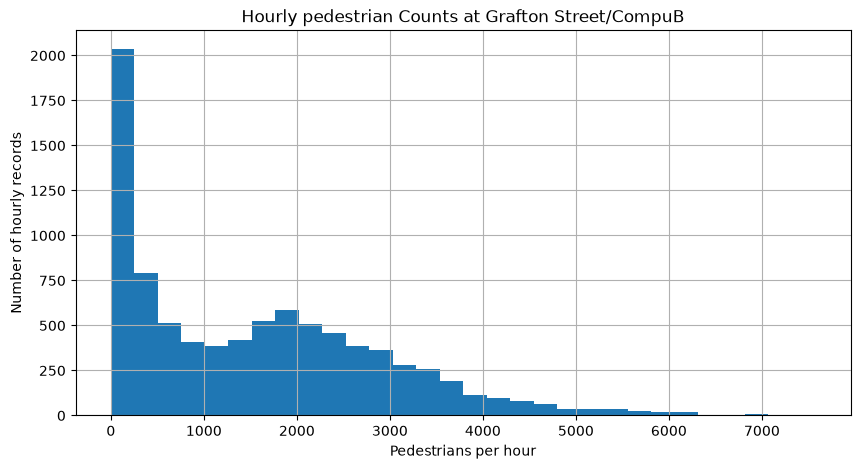

In [64]:
ax = grafton.hist(bins=30, figsize=(10,5))
ax.set_title("Hourly pedestrian Counts at Grafton Street/CompuB")
ax.set_xlabel("Pedestrians per hour")
ax.set_ylabel("Number of hourly records")

the distribution of hourly pedestrian counts at Grafton Street/CompuB was right skewed. The lowest count interval contained approximately 2,000 hourly observations. A second concentration appeared around 1,500 to 2,000 pedestrian per hour, and a small number of observations reached roughly 7,000 pedestrian per hour. 

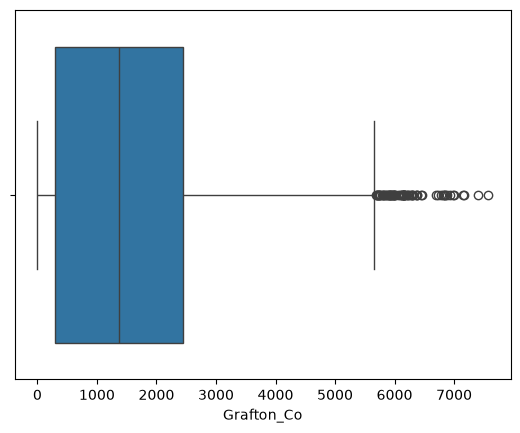

In [65]:
sns.boxplot(data=df_analysis, x="Grafton_Co")
plt.show()

El diagrama de caja muestra varios recuentos horarios de peatones inusualmente altos en la esquina de Grafton Street y CompuB. Estas observaciones podrían representar picos reales en el tráfico peatonal. Las he incluido en el análisis exploratorio y examinaré cuándo ocurrieron para comprender mejor el patrón.


the boxplot shows several unusually high hourly pedestrian counts at Grafton Street/CompuB. These observations may represent genuine peaks in footfall. I retained them for the exploratory analysis and will examine when they occurred to better understand the pattern  

In [81]:
grafton = df_analysis["Grafton_Co"]
q1 = grafton.quantile(0.25)
q3 = grafton.quantile(0.75)
upper_limit = q3 + 1.5 * (q3-q1)
print("upper outliers:",(grafton > upper_limit).sum())

upper outliers: 70


In [85]:
outlier_filter = df_analysis["Grafton_Co"]>upper_limit
print (df_analysis.loc[outlier_filter,["Time","Grafton_Co"]].nlargest(20,"Grafton_Co"))

                   Time  Grafton_Co
521 2025-01-22 17:00:00      7575.0
545 2025-01-23 17:00:00      7405.0
665 2025-01-28 17:00:00      7169.0
344 2025-01-15 08:00:00      7147.0
41  2025-01-02 17:00:00      6998.0
680 2025-01-29 08:00:00      6982.0
666 2025-01-28 18:00:00      6938.0
977 2025-02-10 17:00:00      6875.0
345 2025-01-15 09:00:00      6852.0
690 2025-01-29 18:00:00      6848.0
881 2025-02-06 17:00:00      6834.0
512 2025-01-22 08:00:00      6810.0
712 2025-01-30 16:00:00      6777.0
872 2025-02-06 08:00:00      6727.0
689 2025-01-29 17:00:00      6700.0
713 2025-01-30 17:00:00      6466.0
901 2025-02-07 13:00:00      6445.0
711 2025-01-30 15:00:00      6379.0
848 2025-02-05 08:00:00      6376.0
641 2025-01-27 17:00:00      6352.0


of the highes hourly count at Graafton Street/CompuB, nine occurred at 17:00 and five at 08:00. The highest count was 7,575 pedetrian at 17:00 on January 2025. These observations were retained for further exploratory analysis

In [89]:
outliers_by_hour = df_analysis.loc[outlier_filter, "Time"].dt.hour
print(outliers_by_hour.value_counts().sort_index())

Time
8      7
9      2
10     1
11     2
12     4
13     7
14     2
15     6
16    10
17    21
18     8
Name: count, dtype: int64


upper outliers at Grafton Street/ CompuB were concentrated in the late afternoon. Of the 70 flagged observations, 39 occurred between 16:00 and 18:00 inclusive, with 21 occurring at 17:00

In [91]:
hour = df_analysis ["Time"].dt.hour 
hourly_median = df_analysis.groupby(hour)["Grafton_Co"].median()
print(hourly_median.nlargest(5))

Time
18    3099.0
17    2914.0
19    2466.0
16    2371.0
15    2370.0
Name: Grafton_Co, dtype: float64


The Grafton Street/compuB, the highest median hourly pedestrian count was recorded at 18:00 (3,099 pedestrians), followed by 17:00(2,914 pedestrian). The 17:00 slot had the largest number of unusually high counts, accounting for 21 of the 70 upper outlier 

In [94]:
hour = df_analysis["Time"].dt.hour
day = df_analysis["Time"].dt.day_of_week

weekday = df_analysis[day < 5]
weekend = df_analysis[day >= 5]

weekday_median = weekday.groupby(hour)["Grafton_Co"].median()
weekend_median = weekend.groupby(hour)["Grafton_Co"].median()

print("Weekday peak hour:", weekday_median.idxmax())
print("Weekend peak hour:", weekend_median.idxmax())

Weekday peak hour: 18
Weekend peak hour: 18


In [95]:
print("weekday median at 18:00:", weekday_median.loc[18])
print("weekend median at 18:00:", weekend_median.loc[18])

weekday median at 18:00: 3230.0
weekend median at 18:00: 2895.0


In [ ]:
At Grafton Street/CompuB, the median pedestrian count peaked at 18:00 on both weekdays and weekends. At that hours, the weekdays median was 3